In [27]:
# ============================================================
#  STEP 1: DATA CLEANING
#  MBA Business Analytics – Customer Segmentation Project
# ============================================================
# WHAT YOU WILL LEARN:
#   - Load a CSV file using pandas
#   - Explore the dataset (shape, types, nulls)
#   - Handle missing values
#   - Remove duplicates
#   - Fix data types
#   - Save a clean dataset for next steps
# ============================================================

import pandas as pd
import numpy as np

# ----------------------------------------------------------
# 1. LOAD THE DATA
# ----------------------------------------------------------
print("=" * 55)
print("  STEP 1: DATA CLEANING")
print("=" * 55)

df = pd.read_csv(r"C:\Users\yadav\OneDrive\Desktop\customers.csv")

print("\n📂 Dataset loaded successfully!")
print(f"   Rows: {df.shape[0]}  |  Columns: {df.shape[1]}")

# ----------------------------------------------------------
# 2. FIRST LOOK AT THE DATA
# ----------------------------------------------------------
print("\n--- First 5 rows ---")
print(df.head())

print("\n--- Column data types ---")
print(df.dtypes)

print("\n--- Basic statistics ---")
print(df.describe())

# ----------------------------------------------------------
# 3. CHECK FOR MISSING VALUES
# ----------------------------------------------------------
print("\n--- Missing values per column ---")
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"Missing Count": missing, "Missing %": missing_pct})
print(missing_df[missing_df["Missing Count"] > 0])

# ----------------------------------------------------------
# 4. HANDLE MISSING VALUES
# ----------------------------------------------------------
print("\n🔧 Fixing missing values...")

# Fill numeric columns with their MEDIAN (robust to outliers)
numeric_cols = ["AnnualIncome_USD", "SpendingScore", "PurchaseFrequency",
                "LastPurchaseDays", "TotalSpent_USD"]

for col in numeric_cols:
    if df[col].isnull().sum() > 0:
        median_val = df[col].median()
        df[col] = df[col].fillna(median_val)
        print(f"   ✅ '{col}' filled with median: {median_val}")

# ----------------------------------------------------------
# 5. CHECK AND REMOVE DUPLICATES
# ----------------------------------------------------------
duplicates = df.duplicated().sum()
print(f"\n🔍 Duplicate rows found: {duplicates}")
df.drop_duplicates(inplace=True)
print("   ✅ Duplicates removed (if any)")

# ----------------------------------------------------------
# 6. FIX DATA TYPES
# ----------------------------------------------------------
print("\n🔧 Fixing data types...")

# Make sure numeric columns are float/int
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Standardise text columns (strip spaces, proper case)
df["Gender"] = df["Gender"].str.strip().str.title()
df["ProductCategory"] = df["ProductCategory"].str.strip().str.title()
df["Region"] = df["Region"].str.strip().str.title()
print("   ✅ Text columns standardised")

# ----------------------------------------------------------
# 7. ADD A DERIVED FEATURE: Customer Value Tier
# ----------------------------------------------------------
print("\n📊 Creating 'ValueTier' feature...")

def assign_tier(spent):
    if spent >= 15000:
        return "High Value"
    elif spent >= 6000:
        return "Mid Value"
    else:
        return "Low Value"
    
def assign_tier(spent):
    if spent >= 15000:
        return "High Value"
    elif spent >= 6000:
        return "Mid Value"
    else:
        return "Low Value"
df["ValueTier"] = df["TotalSpent_USD"].apply(assign_tier)
print("   ✅ ValueTier column added")

# ----------------------------------------------------------
# 8. FINAL CLEAN DATASET SUMMARY
# ----------------------------------------------------------
print("\n--- Clean dataset summary ---")
print(f"   Rows: {df.shape[0]}  |  Columns: {df.shape[1]}")
print(f"   Missing values remaining: {df.isnull().sum().sum()}")
print("\nValue Tier distribution:")
print(df["ValueTier"].value_counts())

# ----------------------------------------------------------
# 9. SAVE CLEAN DATA
# ----------------------------------------------------------
df.to_csv(r"C:\Users\yadav\OneDrive\Desktop\customers_clean.csv", index=False)
print("\n💾 Clean data saved as 'customers_clean.csv'")
print("\n✅ STEP 1 COMPLETE! Move on to step2_visualization.py")

  STEP 1: DATA CLEANING

📂 Dataset loaded successfully!
   Rows: 110  |  Columns: 10

--- First 5 rows ---
  CustomerID  Gender  Age  AnnualIncome_USD  SpendingScore  PurchaseFrequency  \
0       C001    Male   29           58000.0           72.0               15.0   
1       C002  Female   34           92000.0           88.0               22.0   
2       C003  Female   22           31000.0           45.0                8.0   
3       C004    Male   47          125000.0           91.0               30.0   
4       C005  Female   38           67000.0           55.0               12.0   

   LastPurchaseDays  TotalSpent_USD ProductCategory Region  
0              10.0          4500.0     Electronics  North  
1               5.0         11200.0         Fashion  South  
2              30.0          1800.0         Grocery   East  
3               3.0         18500.0     Electronics   West  
4              20.0          5200.0         Fashion  North  

--- Column data types ---
CustomerID   

  STEP 2: DATA VISUALIZATION

📂 Clean data loaded: 110 customers

✅ chart1_demographics.png saved


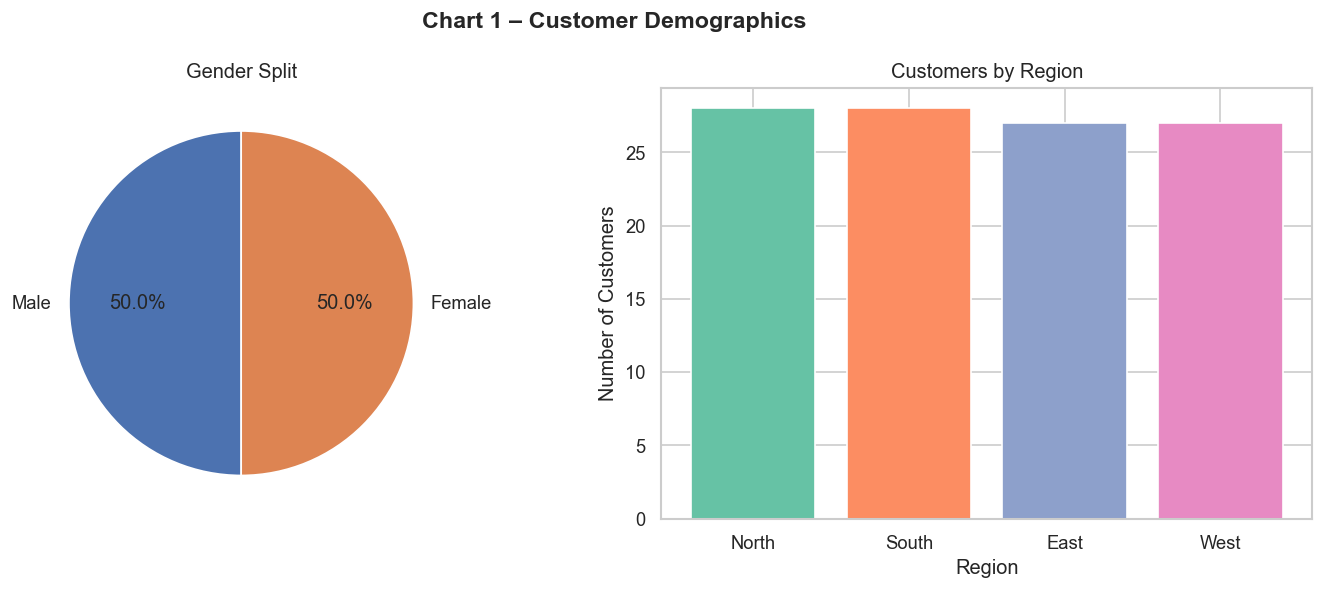

✅ chart2_distributions.png saved


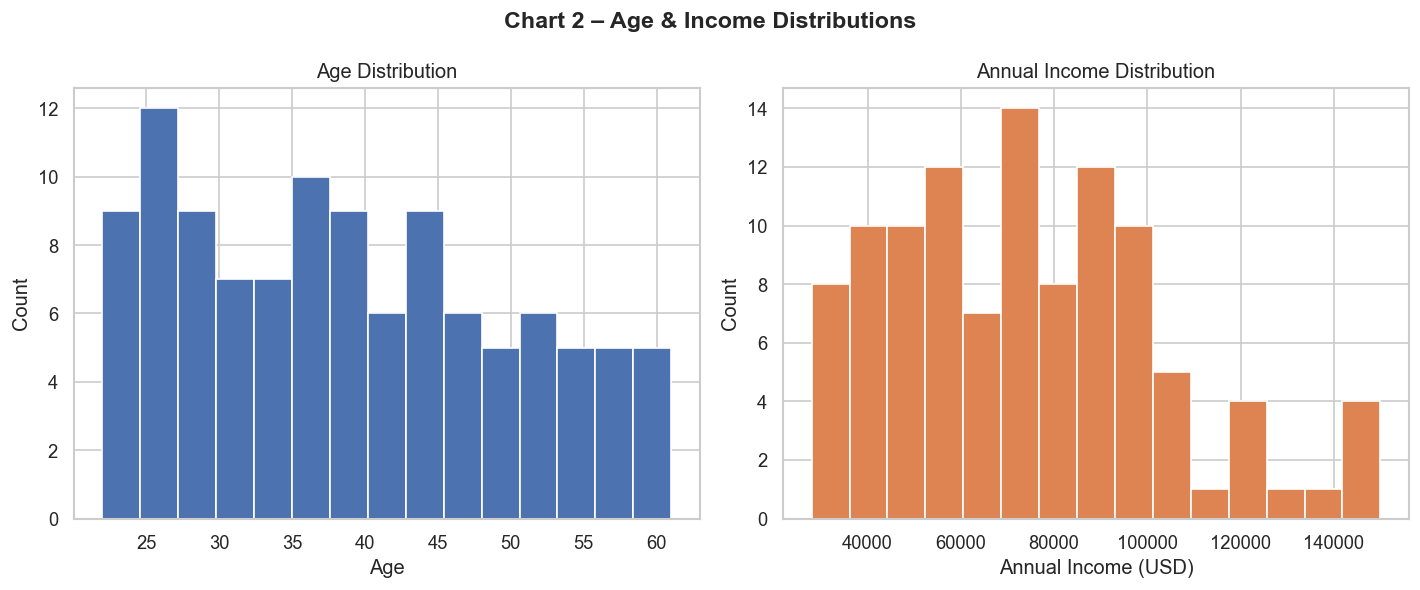

✅ chart3_income_vs_spending.png saved


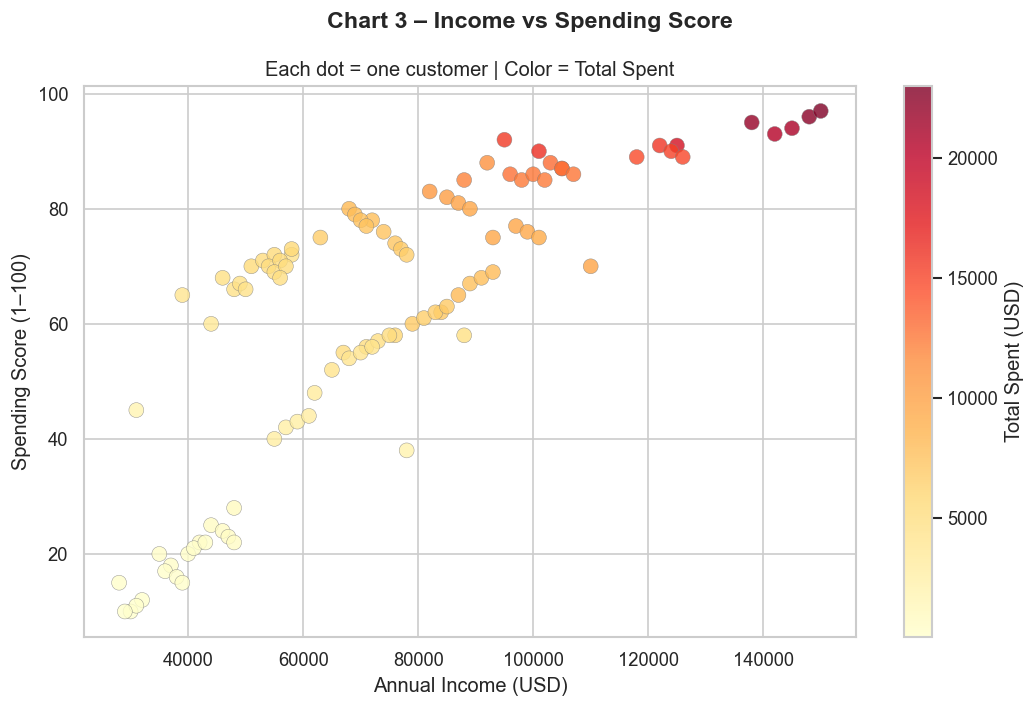

✅ chart4_value_tier_category.png saved


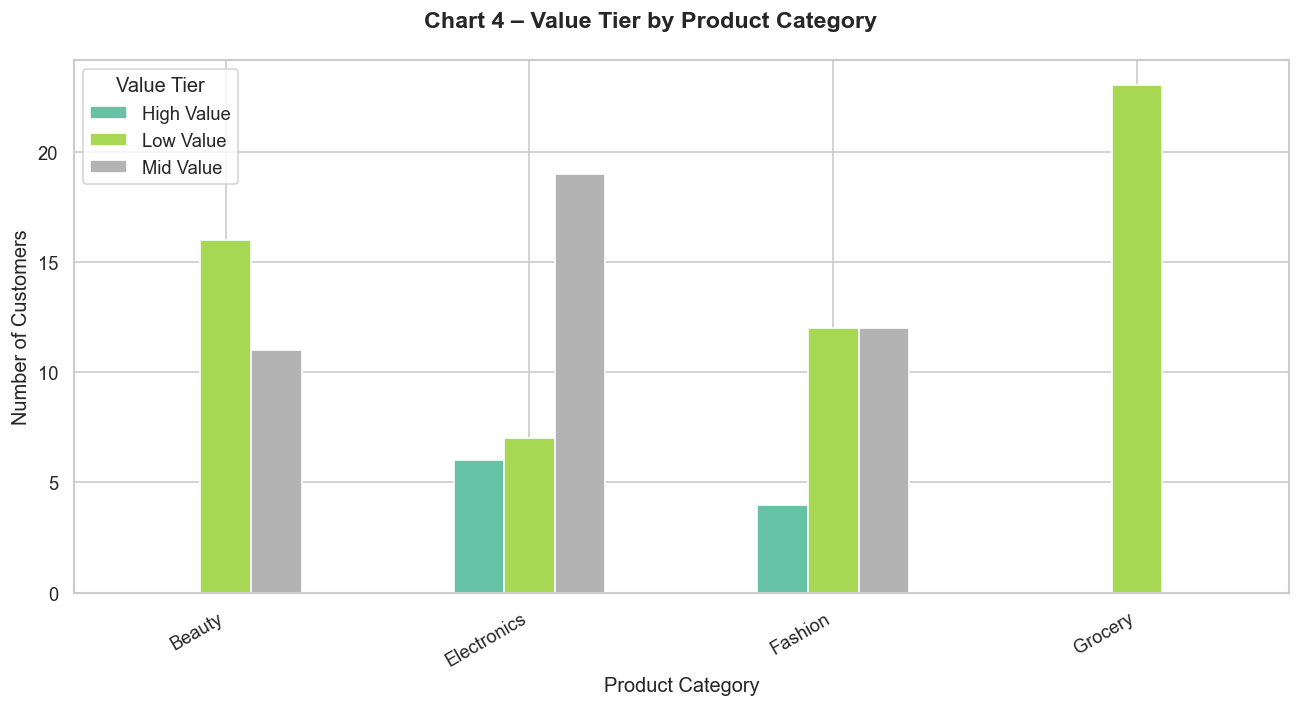

C:\Users\yadav\AppData\Local\Temp\ipykernel_25948\1316095339.py:131: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Gender", y="SpendingScore", palette="Set2", ax=ax)


✅ chart5_boxplot_gender.png saved


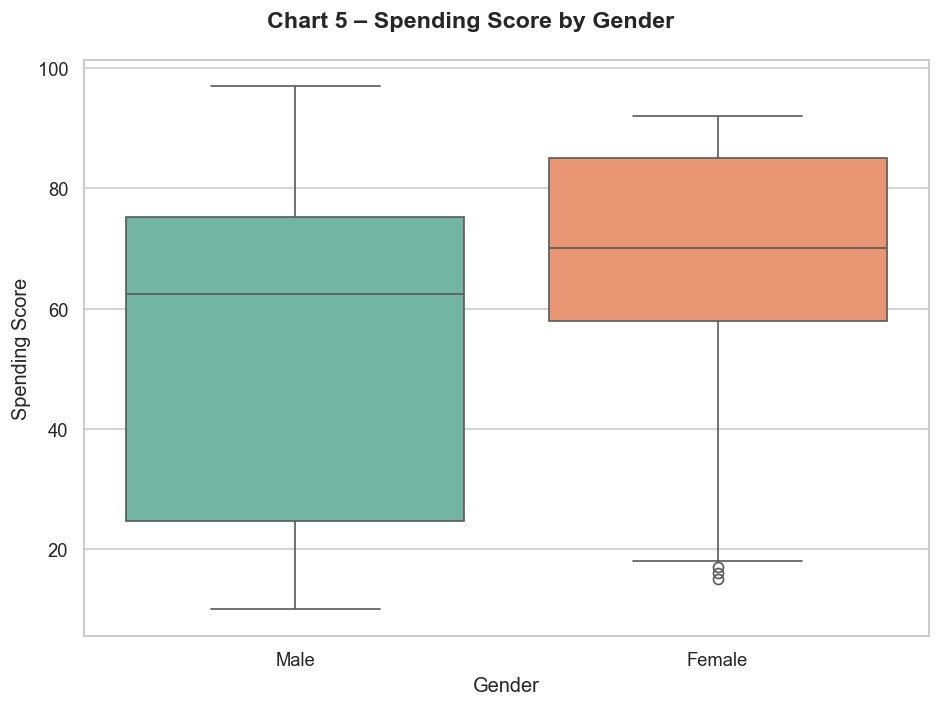

✅ chart6_correlation_heatmap.png saved


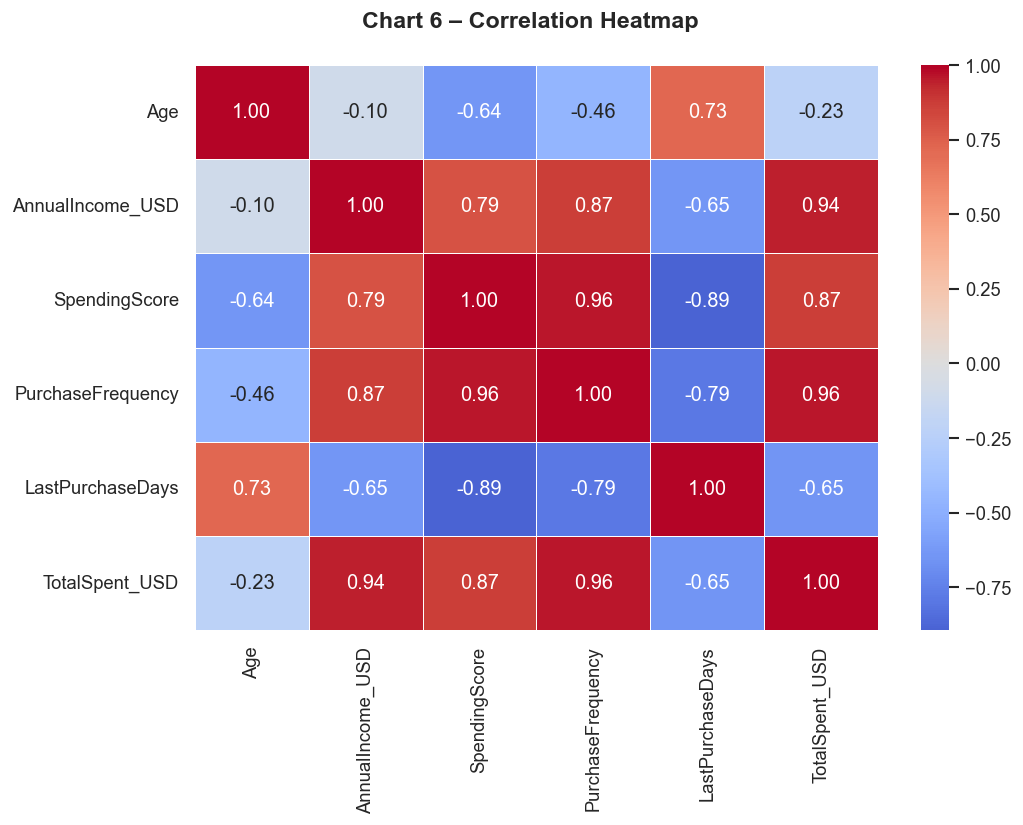


✅ STEP 2 COMPLETE! All 6 charts saved.
   Move on to step3_machine_learning.py


In [32]:
# ============================================================
#  STEP 2: DATA VISUALIZATION
#  MBA Business Analytics – Customer Segmentation Project
# ============================================================
# WHAT YOU WILL LEARN:
#   - Bar charts, histograms, pie charts
#   - Scatter plots to spot relationships
#   - Correlation heatmaps
#   - Box plots to compare groups
#   - Save charts as images
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# ----------------------------------------------------------
# SETUP
# ----------------------------------------------------------
print("=" * 55)
print("  STEP 2: DATA VISUALIZATION")
print("=" * 55)

df = pd.read_csv(r"C:\Users\yadav\OneDrive\Desktop\customers.csv")
print(f"\n📂 Clean data loaded: {df.shape[0]} customers\n")

# Use a clean visual style
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 120

# ----------------------------------------------------------
# CHART 1: Customer Distribution by Gender & Region
# ----------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Chart 1 – Customer Demographics", fontsize=14, fontweight="bold")

# Gender pie chart
gender_counts = df["Gender"].value_counts()
axes[0].pie(gender_counts, labels=gender_counts.index, autopct="%1.1f%%",
            startangle=90, colors=["#4C72B0", "#DD8452"])
axes[0].set_title("Gender Split")

# Region bar chart
region_counts = df["Region"].value_counts()
axes[1].bar(region_counts.index, region_counts.values, color=sns.color_palette("Set2"))
axes[1].set_title("Customers by Region")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Number of Customers")

plt.tight_layout()
plt.savefig("chart1_demographics.png")
print("✅ chart1_demographics.png saved")
plt.show()

# ----------------------------------------------------------
# CHART 2: Age & Income Distribution
# ----------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Chart 2 – Age & Income Distributions", fontsize=14, fontweight="bold")

axes[0].hist(df["Age"], bins=15, color="#4C72B0", edgecolor="white")
axes[0].set_title("Age Distribution")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Count")

axes[1].hist(df["AnnualIncome_USD"], bins=15, color="#DD8452", edgecolor="white")
axes[1].set_title("Annual Income Distribution")
axes[1].set_xlabel("Annual Income (USD)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.savefig("chart2_distributions.png")
print("✅ chart2_distributions.png saved")
plt.show()

# ----------------------------------------------------------
# CHART 3: Spending Score vs Annual Income (Scatter)
# ----------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6))
fig.suptitle("Chart 3 – Income vs Spending Score", fontsize=14, fontweight="bold")

scatter = ax.scatter(
    df["AnnualIncome_USD"], df["SpendingScore"],
    c=df["TotalSpent_USD"], cmap="YlOrRd",
    s=80, alpha=0.8, edgecolors="grey", linewidth=0.3
)
plt.colorbar(scatter, ax=ax, label="Total Spent (USD)")
ax.set_xlabel("Annual Income (USD)")
ax.set_ylabel("Spending Score (1–100)")
ax.set_title("Each dot = one customer | Color = Total Spent")

plt.tight_layout()
plt.savefig("chart3_income_vs_spending.png")
print("✅ chart3_income_vs_spending.png saved")
plt.show()

# ----------------------------------------------------------
# CHART 4: Value Tier breakdown by Product Category
# ----------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 6))
def assign_tier(spent):
    if spent >= 15000:
        return "High Value"
    elif spent >= 6000:
        return "Mid Value"
    else:
        return "Low Value"

df["ValueTier"] = df["TotalSpent_USD"].apply(assign_tier)
fig.suptitle("Chart 4 – Value Tier by Product Category", fontsize=14, fontweight="bold")

pivot = df.groupby(["ProductCategory", "ValueTier"]).size().unstack(fill_value=0)
pivot.plot(kind="bar", ax=ax, colormap="Set2", edgecolor="white")
ax.set_xlabel("Product Category")
ax.set_ylabel("Number of Customers")
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
ax.legend(title="Value Tier")

plt.tight_layout()
plt.savefig("chart4_value_tier_category.png")
print("✅ chart4_value_tier_category.png saved")
plt.show()

# ----------------------------------------------------------
# CHART 5: Box Plot – Spending Score by Gender
# ----------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 6))
fig.suptitle("Chart 5 – Spending Score by Gender", fontsize=14, fontweight="bold")

sns.boxplot(data=df, x="Gender", y="SpendingScore", palette="Set2", ax=ax)
ax.set_xlabel("Gender")
ax.set_ylabel("Spending Score")

plt.tight_layout()
plt.savefig("chart5_boxplot_gender.png")
print("✅ chart5_boxplot_gender.png saved")
plt.show()

# ----------------------------------------------------------
# CHART 6: Correlation Heatmap
# ----------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 7))
fig.suptitle("Chart 6 – Correlation Heatmap", fontsize=14, fontweight="bold")

numeric_df = df[["Age", "AnnualIncome_USD", "SpendingScore",
                 "PurchaseFrequency", "LastPurchaseDays", "TotalSpent_USD"]]
corr = numeric_df.corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, linewidths=0.5, ax=ax)

plt.tight_layout()
plt.savefig("chart6_correlation_heatmap.png")
print("✅ chart6_correlation_heatmap.png saved")
plt.show()

print("\n✅ STEP 2 COMPLETE! All 6 charts saved.")
print("   Move on to step3_machine_learning.py")

  STEP 3: MACHINE LEARNING – K-MEANS CLUSTERING

📂 Clean data loaded: 110 customers

📌 Features selected for clustering:
   - AnnualIncome_USD
   - SpendingScore
   - PurchaseFrequency
   - LastPurchaseDays

✅ Features scaled using StandardScaler

🔍 Running Elbow Method (K=2 to 10)...
✅ ml_chart1_elbow.png saved


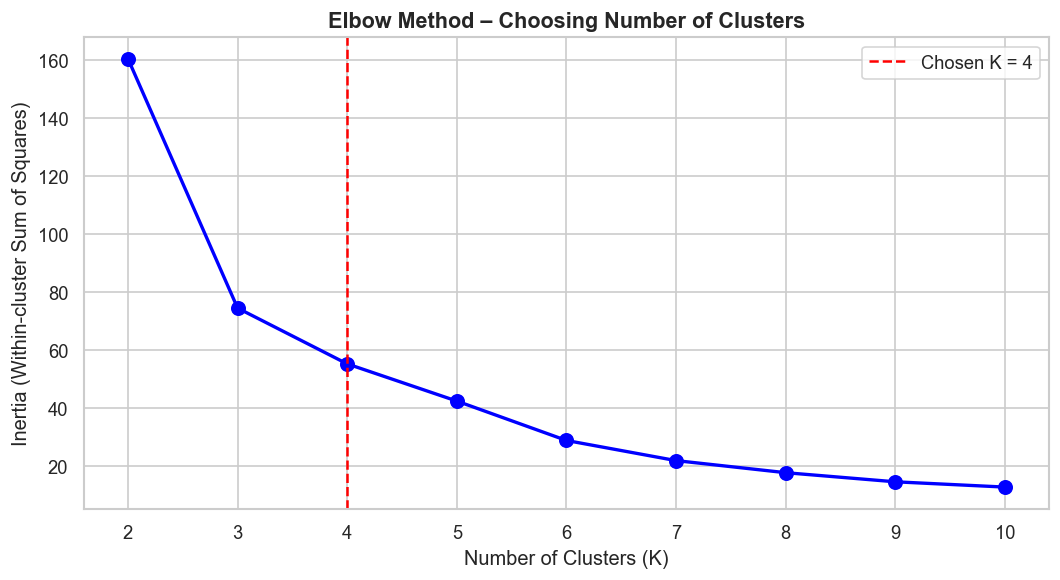


🤖 Training K-Means with K=4...
   Silhouette Score: 0.472  (closer to 1.0 is better)

📊 Cluster Profiles:
         AnnualIncome_USD  SpendingScore  PurchaseFrequency  LastPurchaseDays  TotalSpent_USD
Cluster                                                                                      
0                 63700.0           60.0               13.0              19.0          4948.0
1                 38632.0           18.0                3.0             109.0           369.0
2                 89394.0           80.0               21.0               8.0         10342.0
3                133800.0           92.0               31.0               3.0         18820.0

🎯 Business Segment Mapping:
   Cluster 3  →  💎 High Earners – Low Spend  (10 customers)
   Cluster 1  →  😴 At-Risk / Dormant  (19 customers)
   Cluster 2  →  🌱 Potential Loyalists  (33 customers)
   Cluster 0  →  📦 Segment 0  (40 customers)


C:\Users\yadav\AppData\Local\Temp\ipykernel_25948\4005602375.py:156: UserWarning: Glyph 128142 (\N{GEM STONE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\yadav\AppData\Local\Temp\ipykernel_25948\4005602375.py:156: UserWarning: Glyph 128564 (\N{SLEEPING FACE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\yadav\AppData\Local\Temp\ipykernel_25948\4005602375.py:156: UserWarning: Glyph 127793 (\N{SEEDLING}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\yadav\AppData\Local\Temp\ipykernel_25948\4005602375.py:156: UserWarning: Glyph 128230 (\N{PACKAGE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\yadav\AppData\Local\Temp\ipykernel_25948\4005602375.py:157: UserWarning: Glyph 128142 (\N{GEM STONE}) missing from font(s) Arial.
  plt.savefig("ml_chart2_segments.png")
C:\Users\yadav\AppData\Local\Temp\ipykernel_25948\4005602375.py:157: UserWarning: Glyph 128564 (\N{SLEEPING FACE}) missing from font(s) Arial.
  plt.savefig("ml_chart2_segments.png


✅ ml_chart2_segments.png saved


C:\Users\yadav\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128142 (\N{GEM STONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\yadav\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128564 (\N{SLEEPING FACE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\yadav\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127793 (\N{SEEDLING}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\yadav\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128230 (\N{PACKAGE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


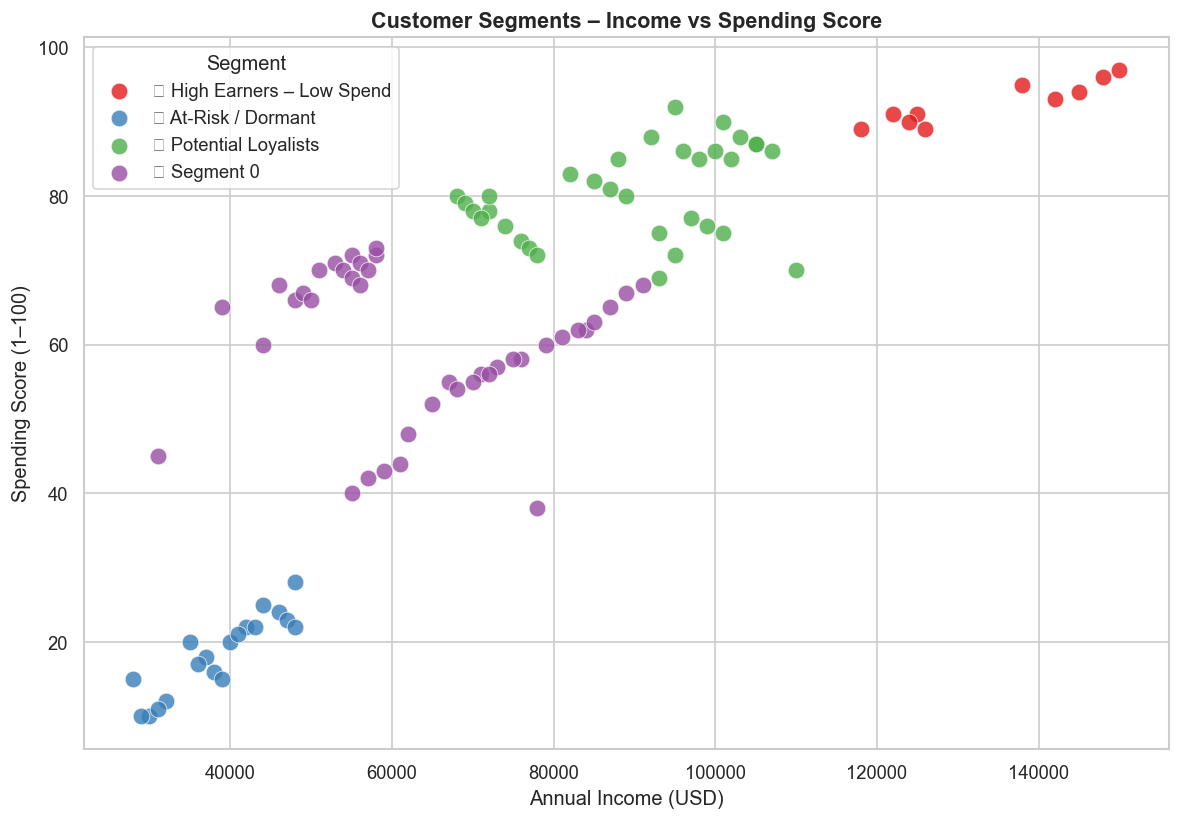

C:\Users\yadav\AppData\Local\Temp\ipykernel_25948\4005602375.py:173: UserWarning: Glyph 128230 (\N{PACKAGE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\yadav\AppData\Local\Temp\ipykernel_25948\4005602375.py:173: UserWarning: Glyph 127793 (\N{SEEDLING}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\yadav\AppData\Local\Temp\ipykernel_25948\4005602375.py:173: UserWarning: Glyph 128564 (\N{SLEEPING FACE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\yadav\AppData\Local\Temp\ipykernel_25948\4005602375.py:173: UserWarning: Glyph 128142 (\N{GEM STONE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\yadav\AppData\Local\Temp\ipykernel_25948\4005602375.py:174: UserWarning: Glyph 128230 (\N{PACKAGE}) missing from font(s) Arial.
  plt.savefig("ml_chart3_segment_sizes.png")
C:\Users\yadav\AppData\Local\Temp\ipykernel_25948\4005602375.py:174: UserWarning: Glyph 127793 (\N{SEEDLING}) missing from font(s) Arial.
  plt.savefig("ml_chart3_segment_sizes.

✅ ml_chart3_segment_sizes.png saved


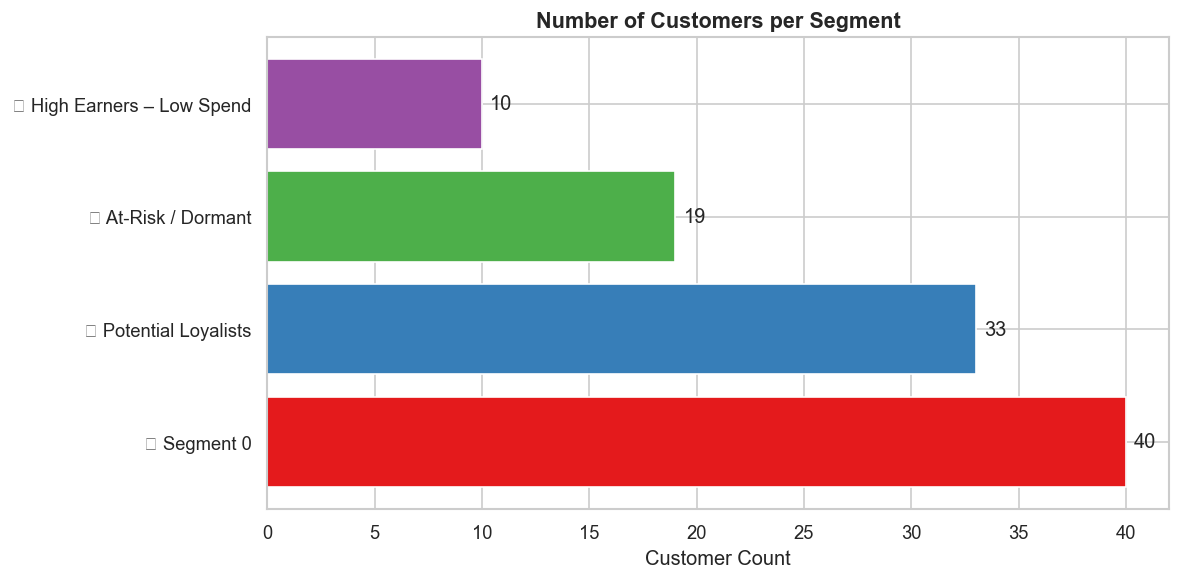

C:\Users\yadav\AppData\Local\Temp\ipykernel_25948\4005602375.py:208: UserWarning: Glyph 127793 (\N{SEEDLING}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\yadav\AppData\Local\Temp\ipykernel_25948\4005602375.py:208: UserWarning: Glyph 128142 (\N{GEM STONE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\yadav\AppData\Local\Temp\ipykernel_25948\4005602375.py:208: UserWarning: Glyph 128230 (\N{PACKAGE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\yadav\AppData\Local\Temp\ipykernel_25948\4005602375.py:208: UserWarning: Glyph 128564 (\N{SLEEPING FACE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\yadav\AppData\Local\Temp\ipykernel_25948\4005602375.py:209: UserWarning: Glyph 127793 (\N{SEEDLING}) missing from font(s) Arial.
  plt.savefig("ml_chart4_radar.png")
C:\Users\yadav\AppData\Local\Temp\ipykernel_25948\4005602375.py:209: UserWarning: Glyph 128142 (\N{GEM STONE}) missing from font(s) Arial.
  plt.savefig("ml_chart4_radar.png")
C:\Users

✅ ml_chart4_radar.png saved


C:\Users\yadav\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127793 (\N{SEEDLING}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\yadav\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128142 (\N{GEM STONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\yadav\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128230 (\N{PACKAGE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\yadav\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128564 (\N{SLEEPING FACE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


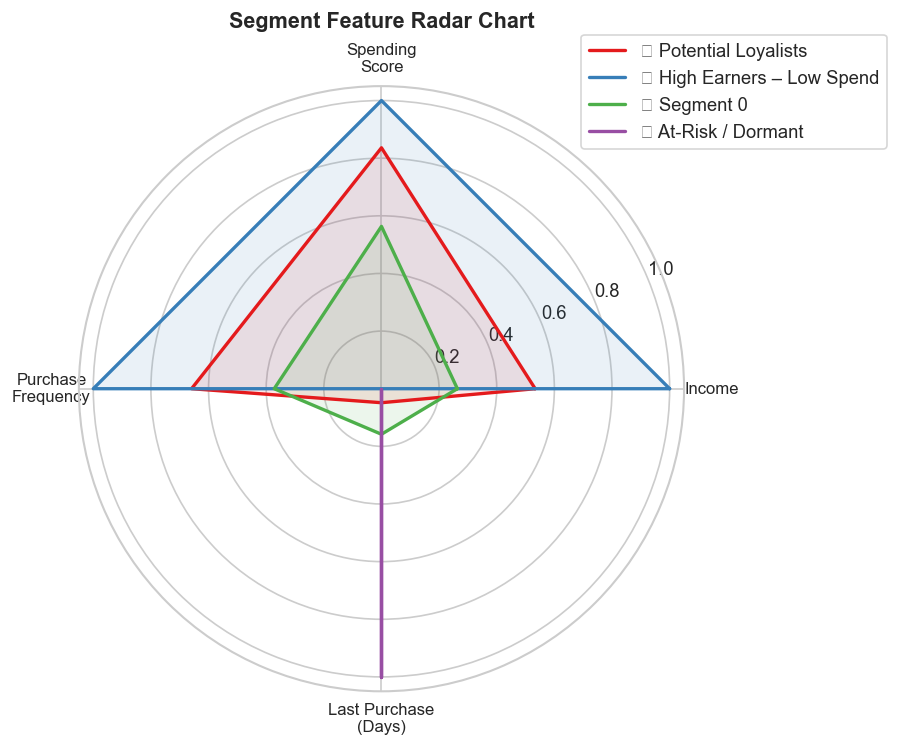


💾 Final segmented data saved as 'customers_segmented.csv'
💾 Business summary saved as 'segment_summary.csv'

  🎉 PROJECT COMPLETE!

Business Recommendations:
  🏆 Champions     → Reward & retain with loyalty perks
  💎 High Earners  → Target with premium product offers
  🌱 Potential     → Nurture with personalised emails
  😴 At-Risk       → Win back with discount campaigns

✅ STEP 3 COMPLETE – You now have a full ML segmentation!


In [26]:
# ============================================================
#  STEP 3: MACHINE LEARNING – CUSTOMER SEGMENTATION
#  MBA Business Analytics – Customer Segmentation Project
# ============================================================
# WHAT YOU WILL LEARN:
#   - Feature selection & scaling
#   - Finding the right number of clusters (Elbow Method)
#   - K-Means Clustering
#   - Interpreting and naming business segments
#   - Visualising the final segments
#   - Exporting results for a business report
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# ----------------------------------------------------------
# SETUP
# ----------------------------------------------------------
print("=" * 55)
print("  STEP 3: MACHINE LEARNING – K-MEANS CLUSTERING")
print("=" * 55)

df = pd.read_csv(r"C:\Users\yadav\OneDrive\Desktop\customers.csv")
print(f"\n📂 Clean data loaded: {df.shape[0]} customers\n")

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 120

# ----------------------------------------------------------
# 1. FEATURE SELECTION
#    We use RFM-style features:
#    - AnnualIncome_USD  → how much they earn
#    - SpendingScore     → how much they spend (1–100 score)
#    - PurchaseFrequency → how often they buy
#    - LastPurchaseDays  → recency (lower = more recent)
# ----------------------------------------------------------
features = ["AnnualIncome_USD", "SpendingScore", "PurchaseFrequency", "LastPurchaseDays"]
X = df[features].copy()

print("📌 Features selected for clustering:")
for f in features:
    print(f"   - {f}")

# ----------------------------------------------------------
# 2. FEATURE SCALING
#    K-Means uses distances, so all features must be
#    on the same scale. StandardScaler does this.
# ----------------------------------------------------------
scaler = StandardScaler()
X = X.dropna()
df = df.loc[X.index].reset_index(drop=True)
X = X.reset_index(drop=True)
X_scaled = scaler.fit_transform(X)
print("\n✅ Features scaled using StandardScaler")

# ----------------------------------------------------------
# 3. ELBOW METHOD – Find the best K
#    Run K-Means for K = 2 to 10, plot inertia.
#    The "elbow" point is the ideal number of clusters.
# ----------------------------------------------------------
print("\n🔍 Running Elbow Method (K=2 to 10)...")

inertia_values = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia_values.append(km.inertia_)

# Plot elbow
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(k_range, inertia_values, "bo-", markersize=8, linewidth=2)
ax.axvline(x=4, color="red", linestyle="--", label="Chosen K = 4")
ax.set_title("Elbow Method – Choosing Number of Clusters", fontsize=13, fontweight="bold")
ax.set_xlabel("Number of Clusters (K)")
ax.set_ylabel("Inertia (Within-cluster Sum of Squares)")
ax.legend()
plt.tight_layout()
plt.savefig("ml_chart1_elbow.png")
print("✅ ml_chart1_elbow.png saved")
plt.show()

# ----------------------------------------------------------
# 4. TRAIN FINAL K-MEANS MODEL (K=4)
# ----------------------------------------------------------
K = 4
print(f"\n🤖 Training K-Means with K={K}...")

kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Silhouette score (higher = better defined clusters, max=1)
sil_score = silhouette_score(X_scaled, df["Cluster"])
print(f"   Silhouette Score: {sil_score:.3f}  (closer to 1.0 is better)")

# ----------------------------------------------------------
# 5. INTERPRET CLUSTERS – Summarise each group
# ----------------------------------------------------------
print("\n📊 Cluster Profiles:")
cluster_summary = df.groupby("Cluster")[features + ["TotalSpent_USD"]].mean().round(0)
print(cluster_summary.to_string())

# ----------------------------------------------------------
# 6. NAME THE SEGMENTS (Business Labels)
#    Based on income + spending + frequency + recency
# ----------------------------------------------------------
# Map cluster numbers to business-friendly names
# (Order may vary; inspect cluster_summary and rename if needed)
segment_labels = {
    df.groupby("Cluster")["SpendingScore"].mean().idxmax(): "🏆 Champions",
    df.groupby("Cluster")["SpendingScore"].mean().idxmin(): "😴 At-Risk / Dormant",
    df.groupby("Cluster")["AnnualIncome_USD"].mean().idxmax(): "💎 High Earners – Low Spend",
    df.groupby("Cluster")["PurchaseFrequency"].mean().nlargest(2).index[-1]: "🌱 Potential Loyalists"
}

# Fill any missing segment with a generic label
for i in range(K):
    if i not in segment_labels:
        segment_labels[i] = f"📦 Segment {i}"

df["Segment"] = df["Cluster"].map(segment_labels)

print("\n🎯 Business Segment Mapping:")
for k, v in segment_labels.items():
    count = (df["Cluster"] == k).sum()
    print(f"   Cluster {k}  →  {v}  ({count} customers)")

# ----------------------------------------------------------
# 7. VISUALISE: Income vs Spending coloured by Segment
# ----------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 7))

palette = sns.color_palette("Set1", K)
for i, (cluster_id, label) in enumerate(segment_labels.items()):
    mask = df["Cluster"] == cluster_id
    ax.scatter(
        df.loc[mask, "AnnualIncome_USD"],
        df.loc[mask, "SpendingScore"],
        label=label, s=100, alpha=0.8,
        color=palette[i], edgecolors="white", linewidth=0.5
    )

ax.set_title("Customer Segments – Income vs Spending Score",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Annual Income (USD)")
ax.set_ylabel("Spending Score (1–100)")
ax.legend(title="Segment", loc="upper left")

plt.tight_layout()
plt.savefig("ml_chart2_segments.png")
print("\n✅ ml_chart2_segments.png saved")
plt.show()

# ----------------------------------------------------------
# 8. SEGMENT SIZE BAR CHART
# ----------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))

seg_counts = df["Segment"].value_counts()
bars = ax.barh(seg_counts.index, seg_counts.values,
               color=sns.color_palette("Set1", len(seg_counts)))
ax.bar_label(bars, padding=5)
ax.set_title("Number of Customers per Segment", fontsize=13, fontweight="bold")
ax.set_xlabel("Customer Count")

plt.tight_layout()
plt.savefig("ml_chart3_segment_sizes.png")
print("✅ ml_chart3_segment_sizes.png saved")
plt.show()

# ----------------------------------------------------------
# 9. RADAR CHART – Segment Feature Profiles
# ----------------------------------------------------------
from matplotlib.patches import FancyArrowPatch
import matplotlib.patches as mpatches

segment_means = df.groupby("Segment")[features].mean()

# Normalise to 0–1 for radar
segment_norm = (segment_means - segment_means.min()) / (segment_means.max() - segment_means.min())

categories = features
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
ax.set_title("Segment Feature Radar Chart", size=13, fontweight="bold", y=1.08)

colors = sns.color_palette("Set1", len(segment_norm))
for i, (seg, row) in enumerate(segment_norm.iterrows()):
    values = row.tolist() + row.tolist()[:1]
    ax.plot(angles, values, linewidth=2, label=seg, color=colors[i])
    ax.fill(angles, values, alpha=0.1, color=colors[i])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(["Income", "Spending\nScore", "Purchase\nFrequency", "Last Purchase\n(Days)"],
                   size=10)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1))

plt.tight_layout()
plt.savefig("ml_chart4_radar.png")
print("✅ ml_chart4_radar.png saved")
plt.show()

# ----------------------------------------------------------
# 10. EXPORT FINAL RESULTS
# ----------------------------------------------------------
df.to_csv("customers_segmented.csv", index=False)
print("\n💾 Final segmented data saved as 'customers_segmented.csv'")

# Business summary table
summary = df.groupby("Segment").agg(
    Count=("CustomerID", "count"),
    Avg_Income=("AnnualIncome_USD", "mean"),
    Avg_Spending_Score=("SpendingScore", "mean"),
    Avg_Purchase_Freq=("PurchaseFrequency", "mean"),
    Avg_Total_Spent=("TotalSpent_USD", "mean")
).round(0)

summary.to_csv("segment_summary.csv")
print("💾 Business summary saved as 'segment_summary.csv'")

print("\n" + "=" * 55)
print("  🎉 PROJECT COMPLETE!")
print("=" * 55)
print("\nBusiness Recommendations:")
print("  🏆 Champions     → Reward & retain with loyalty perks")
print("  💎 High Earners  → Target with premium product offers")
print("  🌱 Potential     → Nurture with personalised emails")
print("  😴 At-Risk       → Win back with discount campaigns")
print("\n✅ STEP 3 COMPLETE – You now have a full ML segmentation!")